# Data Visualization — Quiz (Lectures 1–7)

**Time:** 90 minutes 
**Tools:** Plotly only (`plotly.express` first, then `update_traces` / `update_layout` / `update_xaxes` / `update_yaxes`)

**Your task:** answer each analytical question with **one polished, explanatory visualization**. For every question **you decide which chart type fits best** — and justify the choice in one or two sentences.

**Every figure must have:**
1. An **insight title** that states the finding, not just the variables
2. `template='plotly_white'` and a decluttered layout (no unnecessary gridlines, legends or axis titles)
3. A **CVD-safe palette** — no red/green; grey for context + one accent colour where it helps
4. Colour that **encodes meaning**, not decoration
5. Direct labels or annotations where they help the reader

**Chart types covered in the course** — choose from these:
line chart · sorted bar chart · stacked / 100% stacked bar chart · scatter plot · bubble chart · histogram · box plot · violin plot · choropleth map · treemap

> 💡 Each question has one chart type that fits it best, and the questions together cover most of the list above. If two of your answers use the same chart type, check the question again.


**Submit:** this notebook pushed to your personal repo as `quiz/dataviz_quiz.ipynb`

## The dataset — World Population 1970–2022

**Source:** [World Population Dataset](https://www.kaggle.com/datasets/iamsouravbanerjee/world-population-dataset) on Kaggle, compiled from Worldometer (UN World Population Prospects estimates). **234 rows × 16 columns — one row per country or territory, no missing values.**

| Column | Type | Description |
|---|---|---|
| `Country`, `Capital` | categorical | Country / territory and its capital |
| `Continent` | categorical | Africa, Asia, Europe, North America, Oceania, South America |
| `CCA3` | spatial | ISO-3 country code — use with `locationmode='ISO-3'` |
| `1970 Population` … `2022 Population` | temporal | Population in 1970, 1980, 1990, 2000, 2010, 2015, 2020, 2022 |
| `Area` | numerical | Land area in km² |
| `Density` | numerical | People per km² (2022) |
| `World share (%)` | numerical | Share of world population in 2022 |
| `Rank` | numerical | Rank by 2022 population |

**The next setup cell also gives you `df_long` — the same data in **tidy (long) format** with one row per country per year. Use `df` for one-year questions and `df_long` for questions about change over time**

In [1]:
import pandas as pd
import plotly.express as px
import numpy as np

df = pd.read_csv('world_population.csv')

# Shorter column names
df = df.rename(columns={'Country/Territory': 'Country', 'Area (km²)': 'Area',
                        'Density (per km²)': 'Density', 'World Population Percentage': 'World share (%)'})

# Tidy (long) version: one row per country per year
year_cols = [c for c in df.columns if c.endswith('Population')]
df_long = df.melt(id_vars=['CCA3', 'Country', 'Continent'], value_vars=year_cols,
                  var_name='Year', value_name='Population')

df_long['Year'] = df_long['Year'].str[:4].astype(int)     # '2022 Population' → 2022

print(df.shape, df_long.shape)


(234, 16) (1872, 5)


In [2]:
df

,Rank,CCA3,Country,Capital,Continent,2022 Population,2020 Population,2015 Population,2010 Population,2000 Population,1990 Population,1980 Population,1970 Population,Area,Density,World share (%)
0,36,AFG,Afghanistan,Kabul,Asia,41128771,38972230,33753499,28189672,19542982,10694796,12486631,10752971,652230,63.0587,0.52
1,138,ALB,Albania,Tirana,Europe,2842321,2866849,2882481,2913399,3182021,3295066,2941651,2324731,28748,98.8702,0.04
2,34,DZA,Algeria,Algiers,Africa,44903225,43451666,39543154,35856344,30774621,25518074,18739378,13795915,2381741,18.8531,0.56
3,213,ASM,American Samoa,Pago Pago,Oceania,44273,46189,51368,54849,58230,47818,32886,27075,199,222.4774,0.00
4,203,AND,Andorra,Andorra la Vella,Europe,79824,77700,71746,71519,66097,53569,35611,19860,468,170.5641,0.00
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
229,226,WLF,Wallis and Futuna,Mata-Utu,Oceania,11572,11655,12182,13142,14723,13454,11315,9377,142,81.4930,0.00
230,172,ESH,Western Sahara,El Aaiún,Africa,575986,556048,491824,413296,270375,178529,116775,76371,266000,2.1654,0.01
231,46,YEM,Yemen,Sanaa,Asia,33696614,32284046,28516545,24743946,18628700,13375121,9204938,6843607,527968,63.8232,0.42
232,63,ZMB,Zambia,Lusaka,Africa,20017675,18927715,16248230,13792086,9891136,7686401,5720438,4281671,752612,26.5976,0.25


In [3]:
df_long

,CCA3,Country,Continent,Year,Population
0,AFG,Afghanistan,Asia,2022,41128771
1,ALB,Albania,Europe,2022,2842321
2,DZA,Algeria,Africa,2022,44903225
3,ASM,American Samoa,Oceania,2022,44273
4,AND,Andorra,Europe,2022,79824
...,...,...,...,...,...
1867,WLF,Wallis and Futuna,Oceania,1970,9377
1868,ESH,Western Sahara,Africa,1970,76371
1869,YEM,Yemen,Asia,1970,6843607
1870,ZMB,Zambia,Africa,1970,4281671


---
## Q1 — Which continent is growing fastest?

How has the population of each continent **grown since 1970, relative to its 1970 size** — and which continent is growing fastest?


**Chart choice & justification:** *Which chart did you choose, and why? Justify design choices.

**Chart: I used a line chart to show the growth index.**

- **Why a line chart?** Line chart was used because the data here is continuous, showing a change in trajectory of population change over time. This continuous change over years is best represented in a line chart.
- **Why an index (1970 = 1×) and not raw population?** My decision here was to use a growth index rather than raw population, as the question asks for relative growth in population since 1970. This is best represented on a line chart using the growth index parameter.
- **Colour:** We chose to only color Africa, which is the fastest growig continent, other continents were left as grey. This highlighted Africa as the fastest grower to our users.
- **Direct labels instead of a legend:** Only Africa and Europe (the two extremes) are labelled at the end of their lines,  Whereas Asia, the Americas and Oceania are very close together and hence they share one grey label.

Continent
Europe           1.13
North America    1.90
Asia             2.20
South America    2.26
Oceania          2.31
Africa           3.90
Name: Growth, dtype: float64


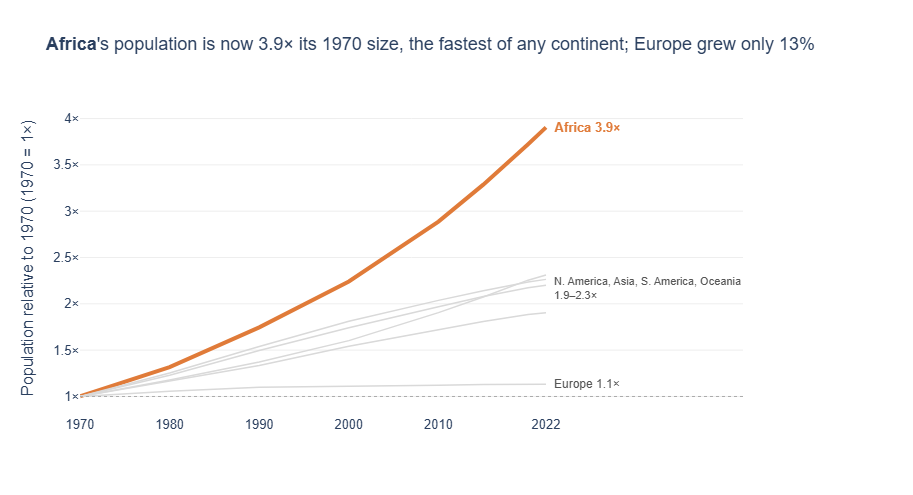

In [5]:
# Q1

# Shared colour roles (CVD-safe course palette)
AFRICA      = '#E07B39'   # orange: Africa, the growth story
ACCENT      = '#2E75B6'   # blue: the one accent of each chart
DARK_GREY   = '#555555'   # secondary story / annotation text
MID_GREY    = '#AAAAAA'
LIGHT_GREY  = '#D9D9D9'   # context
FONT = dict(family='Arial', size=13)

cont = df_long.groupby(['Continent', 'Year'], as_index=False)['Population'].sum()
base_1970 = cont.loc[cont['Year'] == 1970].set_index('Continent')['Population']
cont['Growth'] = cont['Population'] / cont['Continent'].map(base_1970)      # 1.0 = 1970 size

growth_2022 = cont.loc[cont['Year'] == 2022].set_index('Continent')['Growth'].sort_values()
fastest, slowest = growth_2022.idxmax(), growth_2022.idxmin()
middle = growth_2022.drop([fastest, slowest])
print(growth_2022.round(2))

color_map = {c: (AFRICA if c == fastest else LIGHT_GREY) for c in cont['Continent'].unique()}

fig = px.line(
    data_frame=cont,
    x='Year', y='Growth',
    color='Continent',
    color_discrete_map=color_map,
    hover_name='Continent',
    hover_data={'Continent': False, 'Growth': ':.2f', 'Population': ':,'},
    labels={'Growth': 'Population relative to 1970 (1970 = 1×)'},
    title=(f"<b>{fastest}</b>'s population is now {growth_2022[fastest]:.1f}× its 1970 size, the fastest "
           f"of any continent; {slowest} grew only {growth_2022[slowest] - 1:.0%}"),
    template='plotly_white',
    height=480, width=950,
)

fig.update_traces(line_width=1.5)                                    # thin context lines
fig.update_traces(line_width=4, selector={'name': fastest})          # thick highlight line

fig.add_hline(y=1, line_dash='dot', line_color=MID_GREY, line_width=1)

fig.add_annotation(x=2022, y=growth_2022[fastest], text=f'<b>{fastest} {growth_2022[fastest]:.1f}×</b>',
                   showarrow=False, xanchor='left', xshift=6, font=dict(color=AFRICA, size=13))
fig.add_annotation(x=2022, y=growth_2022[slowest], text=f'{slowest} {growth_2022[slowest]:.1f}×',
                   showarrow=False, xanchor='left', xshift=6, font=dict(color=DARK_GREY, size=12))
fig.add_annotation(x=2022, y=middle.mean(),
                   text=f"{', '.join(middle.index.str.replace('North America', 'N. America').str.replace('South America', 'S. America'))}"
                        f"<br>{middle.min():.1f}–{middle.max():.1f}×",
                   showarrow=False, xanchor='left', xshift=6, align='left', font=dict(color=DARK_GREY, size=11))

fig.update_layout(
    showlegend=False,
    font=FONT,
    margin=dict(r=170),                                   # room for the direct labels
    xaxis=dict(showgrid=False, title='', tickvals=[1970, 1980, 1990, 2000, 2010, 2022]),
    yaxis=dict(gridcolor='#EEEEEE', ticksuffix='×', range=[0.8, 4.2], zeroline=False),
)
fig.show()

---
## Q2 — Which countries added the most people?

Which **15 countries added the most people** between 1970 and 2022 — and how many of them are in **Africa**?

**Chart choice & justification:** *Which chart did you choose, and why? Justify design choices.

**Chart: I used sorted horizontal bar chart.**

- **Why bars?** This is a ranking of separate countries by number people added. I thought that the viewers eye will compare bar end points against a shared zero baseline more precisely than angles, hence horizontal bar chart was used. Bars always start at zero, so India's +860 M really does look about 15× Vietnam's +56 M.
- **Why horizontal and sorted?** Since country names are long, horizontal bars keep the labels flat and readable, hence selected
- **Colour encodes the second half of the question:**  I kept the African countries are orange and the rest are grey, so the reader can count the African bars at a glance. The word *Africa* in the title has the same orange, so no legend is needed.
- **Absolute change, not percentage change:** the question asks how many *people* were added, so the bars show 2022 minus 1970 in millions.

4 African countries in the top 15: ['Nigeria', 'Ethiopia', 'DR Congo', 'Egypt']


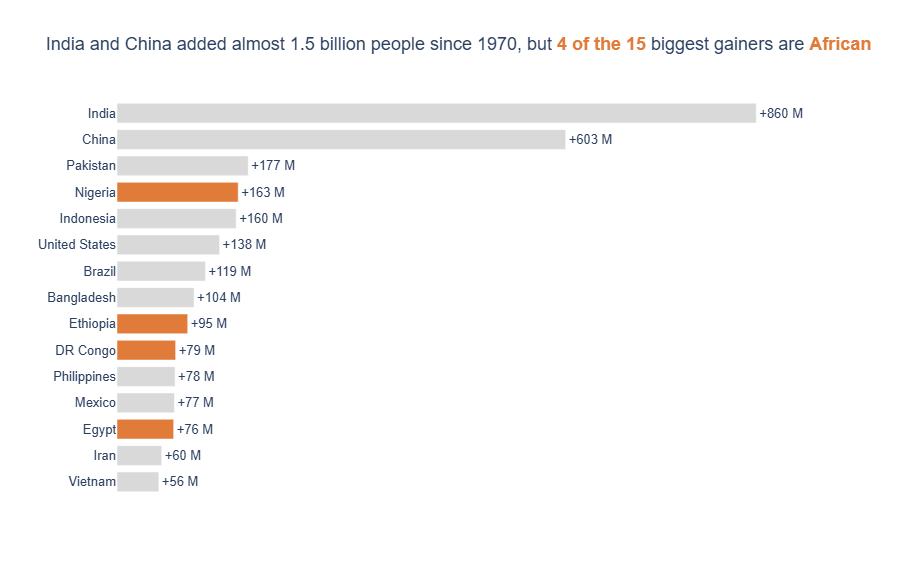

In [6]:
# Q2

added = df.assign(Added=df['2022 Population'] - df['1970 Population'])
top15 = added.nlargest(15, 'Added').copy()
top15['Group'] = np.where(top15['Continent'] == 'Africa', 'Africa', 'Other continents')
top15['Label'] = (top15['Added'] / 1e6).map('+{:,.0f} M'.format)
n_africa = (top15['Group'] == 'Africa').sum()
africa_names = top15.loc[top15['Group'] == 'Africa', 'Country'].tolist()
print(f'{n_africa} African countries in the top 15:', africa_names)

fig = px.bar(
    data_frame=top15,
    x='Added', y='Country',
    orientation='h',
    color='Group',
    color_discrete_map={'Africa': AFRICA, 'Other continents': LIGHT_GREY},
    text='Label',
    category_orders={'Country': top15['Country'].tolist()},     # largest at the top
    hover_name='Country',
    hover_data={'Group': False, 'Label': False, 'Continent': True, 'Added': ':,'},
    labels={'Added': 'People added 1970–2022'},
    title=(f"India and China added almost 1.5 billion people since 1970, but "
           f"<span style='color:{AFRICA}'><b>{n_africa} of the 15</b></span> biggest gainers are "
           f"<span style='color:{AFRICA}'><b>African</b></span>"),
    template='plotly_white',
    height=560, width=950,
)

fig.update_traces(textposition='outside', cliponaxis=False)
fig.update_layout(
    showlegend=False,
    font=FONT,
    bargap=0.25,                                               # bars wider than the gaps
    xaxis=dict(visible=False, range=[0, top15['Added'].max() * 1.12]),   # zero baseline, values labelled
    yaxis=dict(title=''),
)
fig.show()

---
## Q3 — Do bigger countries have more people?

Is there a relationship between a country's **land area** and its **2022 population** — does it differ by **continent**, and which countries clearly break the pattern?

**Chart choice & justification:** *Which chart did you choose, and why? Justify design choices.

**Chart: I used scatter plot, both axes on a log scale, with a fitted trend line.**

- **Why a scatter?** The question I answer here is about the relationship between two continuous variables (area and population), looking for patterns between the variables. Hence scatter plot best visualises the patterns in the data
- **Why log-log?** Log is used so that large variables do not dominate the other variables and the graph is more standardised. Area runs from 1 km² (Vatican) to 17 million km² (Russia), and population from about 500 to 1.4 billion. On log scales the relationship becomes a straight line and the outliers become visible.
- **Trend line as reference:** a dashed grey least-squares line on the log values shows the typical pattern (about 10× the area gives about 5× the people). This way the viewer can judge which countries sit above or below expectation. It is grey so it doesn't compete with the data.
- **Annotations only for the countries that break the pattern most** (Bangladesh above the line, Greenland and the Falklands below it, Singapore as the city-state extreme). Labelling every point would be clutter.
- **Legend kept on purpose:** six continents can't be labelled directly on a scatter, so a single horizontal legend sits above the plot with no title.

slope = 0.72, r = 0.87
Continent
South America    0.28
Oceania          0.33
North America    0.78
Africa           0.99
Europe           1.18
Asia             2.47
Name: vs_trend, dtype: float64


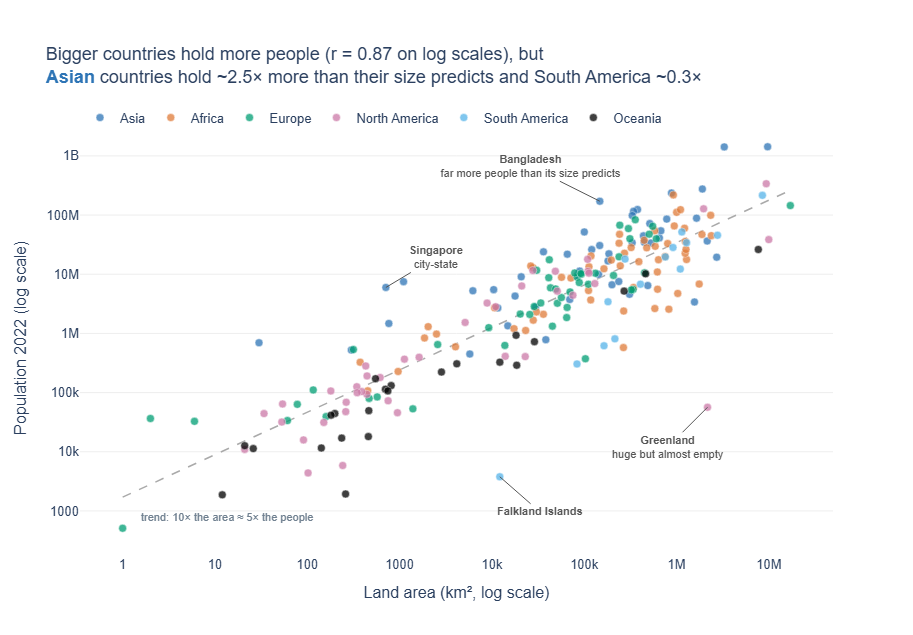

In [7]:
# Q3

q3 = df.copy()
log_area, log_pop = np.log10(q3['Area']), np.log10(q3['2022 Population'])
b, a = np.polyfit(log_area, log_pop, 1)
r = np.corrcoef(log_area, log_pop)[0, 1]
q3['vs_trend'] = 10 ** (log_pop - (a + b * log_area))          # 2.0 = twice the people the trend predicts

by_continent = q3.groupby('Continent')['vs_trend'].apply(lambda s: 10 ** np.log10(s).mean()).sort_values()
print(f'slope = {b:.2f}, r = {r:.2f}');  print(by_continent.round(2))

continent_colors = {'Asia': ACCENT, 'Africa': AFRICA, 'Europe': '#009E73',
                    'North America': '#CC79A7', 'South America': '#56B4E9', 'Oceania': '#000000'}

fig = px.scatter(
    data_frame=q3,
    x='Area', y='2022 Population',
    color='Continent',
    color_discrete_map=continent_colors,
    category_orders={'Continent': ['Asia', 'Africa', 'Europe', 'North America', 'South America', 'Oceania']},
    log_x=True, log_y=True,
    hover_name='Country',
    hover_data={'Continent': True, 'Area': ':,', '2022 Population': ':,', 'vs_trend': ':.2f'},
    labels={'Area': 'Land area (km², log scale)', '2022 Population': 'Population 2022 (log scale)',
            'vs_trend': 'People vs. trend (×)'},
    opacity=0.75,
    title=(f"Bigger countries hold more people (r = {r:.2f} on log scales), but "
           f"<br><span style='color:{ACCENT}'><b>Asian</b></span> countries hold "
           f"~{by_continent['Asia']:.1f}× more than their size predicts and South America ~{by_continent['South America']:.1f}×"),
    template='plotly_white',
    height=620, width=1000,
)

fig.update_traces(marker=dict(size=8, line=dict(width=0.5, color='white')))

xs = np.logspace(log_area.min(), log_area.max(), 50)
fig.add_scatter(x=xs, y=10 ** (a + b * np.log10(xs)), mode='lines',
                line=dict(color=MID_GREY, dash='dash', width=1.5), hoverinfo='skip', showlegend=False)
fig.data = fig.data[-1:] + fig.data[:-1]
fig.add_annotation(x=np.log10(1.5), y=a + b * np.log10(1.5), text=f'trend: 10× the area ≈ {10**b:.0f}× the people',
                   showarrow=False, yshift=-28, xanchor='left', font=dict(color='slategrey', size=11))

for country, ax, ay, note in [('Bangladesh', -70, -35, 'far more people than its size predicts'),
                              ('Singapore', 50, -30, 'city-state'),
                              ('Greenland', -40, 40, 'huge but almost empty'),
                              ('Falkland Islands', 40, 35, '')]:
    row = q3.loc[q3['Country'] == country].iloc[0]
    fig.add_annotation(x=np.log10(row['Area']), y=np.log10(row['2022 Population']),
                       text=f'<b>{country}</b>' + (f'<br>{note}' if note else ''),
                       showarrow=True, arrowhead=0, arrowcolor=DARK_GREY, ax=ax, ay=ay,
                       font=dict(color=DARK_GREY, size=11))

fig.update_layout(
    font=FONT,
    legend=dict(title='', orientation='h', x=0, y=1.04),
    margin=dict(t=120),
    xaxis=dict(showgrid=False, zeroline=False),
    yaxis=dict(gridcolor='#EEEEEE', zeroline=False),
)
fig.show()

---
## Q4 — How crowded are the continents?

How does **population density vary within and across continents**? Show the spread, not just the average.

**Chart choice & justification:** *Which chart did you choose, and why? Justify design choices.

**Chart: I used horizontal box plot per continent, with every country shown as a point, on a log x-axis.**

- **Why a box plot?** In this question we have to compare the spread across six groups, not just the average. Hence a box  plot is used, since it shows the median, the middle 50% (IQR) and the outliers compactly, side by side. 
- **Why a log x-axis instead of capping outliers?** Density runs from 0.03 people/km² (Greenland) to 23,000 (Macau). The outliers here are real (city-states), not errors. Capping at the 95th percentile would hide exactly what makes Asia's and Europe's spread so wide. A log scale shows all of it, and the axis title says it is log.
- **Sorted by median**, I kept most crowded continents are at the top, because continents have no natural order.
- **Colour:** the continent with the highest median gets the blue accent and the others stay grey. This surprises many readers: it is North America, because of its many small, dense Caribbean islands.

Continent
North America    221.4
Asia             123.0
Europe           106.9
Oceania           78.2
Africa            59.7
South America     17.8
Name: Density, dtype: float64


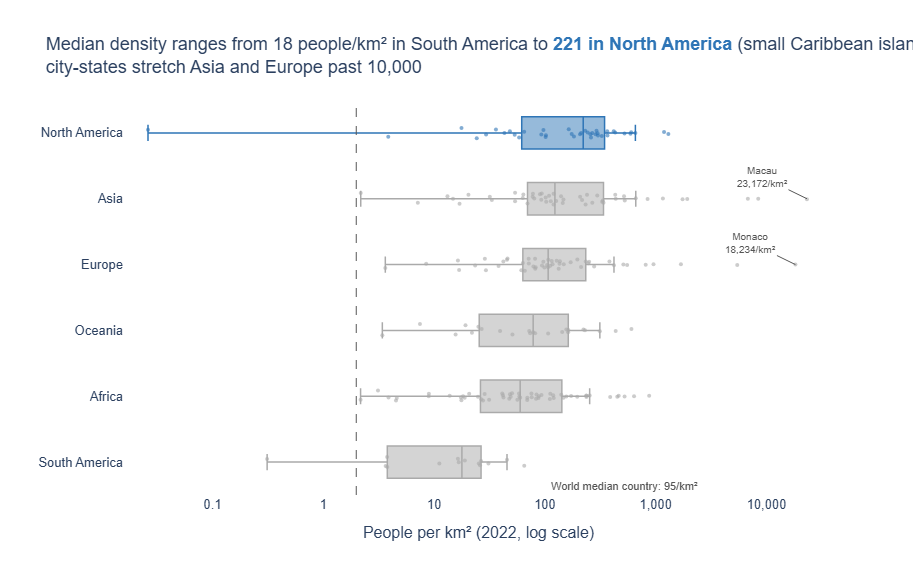

In [9]:
# Q4

medians = df.groupby('Continent')['Density'].median().sort_values(ascending=False)
order = medians.index.tolist()                         # most crowded first (top)
top, bottom = order[0], order[-1]
q4 = df.assign(Group=np.where(df['Continent'] == top, top, 'Other'))
world_median = df['Density'].median()
print(medians.round(1))

fig = px.box(
    data_frame=q4,
    x='Density', y='Continent',
    color='Group',
    color_discrete_map={top: ACCENT, 'Other': MID_GREY},
    category_orders={'Continent': order},
    points='all',                                      # every country visible, not just outliers
    log_x=True,
    hover_name='Country',
    hover_data={'Group': False, 'Density': ':,.1f'},
    labels={'Density': 'People per km² (2022, log scale)'},
    title=(f"Median density ranges from {medians[bottom]:.0f} people/km² in {bottom} to "
           f"<span style='color:{ACCENT}'><b>{medians[top]:.0f} in {top}</b></span> (small Caribbean islands);<br>"
           f"city-states stretch Asia and Europe past 10,000"),
    template='plotly_white',
    height=560, width=1000,
)

fig.update_traces(marker=dict(size=4, opacity=0.6), jitter=0.4, pointpos=0, line_width=1.5)
fig.update_layout(boxmode='overlay')                  # one box per row (colour is not a sub-group)

fig.add_vline(x=np.log10(world_median),                     # shapes on a log axis use log10 units
              line_dash='dash', line_color=DARK_GREY, line_width=1,
              annotation=dict(text=f'World median country: {world_median:.0f}/km²', xanchor='left', xshift=6,
                              yanchor='bottom', font=dict(color=DARK_GREY, size=11)),
              annotation_position='bottom right')

for country in ['Macau', 'Monaco']:
    row = df.loc[df['Country'] == country].iloc[0]
    fig.add_annotation(x=np.log10(row['Density']), y=row['Continent'], text=f"{country}<br>{row['Density']:,.0f}/km²",
                       showarrow=True, arrowhead=0, arrowcolor=DARK_GREY, ax=-45, ay=-22,
                       font=dict(color=DARK_GREY, size=10))

fig.update_layout(
    showlegend=False,
    font=FONT,
    xaxis=dict(showgrid=False, zeroline=False, dtick=1, tickformat=',', range=[-1.8, 4.6]),   # one tick per power of 10
    yaxis=dict(title='', showgrid=False),
)
fig.show()

---
## Q5 — Where did populations grow — and where did they shrink?

Which countries' populations **grew and which shrank between 2000 and 2022** (percentage change), and where in the world are they?

**Chart choice & justification:** *Which chart did you choose, and why? Justify design choices.

**Chart: I used choropleth map (`px.choropleth`) with a diverging colour scale centred on 0%.**

- **Why a map?** The question specifically asks where population growth and decline are happening around the world. The geographic distribution is therefore the main takeaway: population decline is concentrated in Eastern and Southern Europe, while the fastest growth is in Sub-Saharan Africa and the Gulf.
- **Diverging scale:** The data has a clear midpoint at 0%, which represents no population change. Red indicates population decline, blue indicates growth, and white represents values close to zero. This colour scheme works well for all common types of colour vision deficiency, unlike red and green.
- **Deliberately asymmetric range, -40% to +120%:** Population growth reaches +317% in Qatar, while the largest decline is -38%. Using a symmetrical scale of ±317% would make the shrinking countries appear almost white and difficult to distinguish. Instead, the scale uses white at 0% and caps positive growth at +120%, making population losses easier to see while still distinguishing moderate from rapid growth. The cap is clearly explained in the annotation, and the colour bar labels the upper limit as “≥ +120%”.
- **Hover** The chart also includes the actual population figures for 2000 and 2022 alongside the percentage change, making it easy to verify the values. The ISO country code is omitted because it would repeat information already provided by the country name.

34 shrank, 18 of them in Europe; median African growth 78%
                  Country  Change
167                 Qatar   317.0
219  United Arab Emirates   188.0
59      Equatorial Guinea   145.0


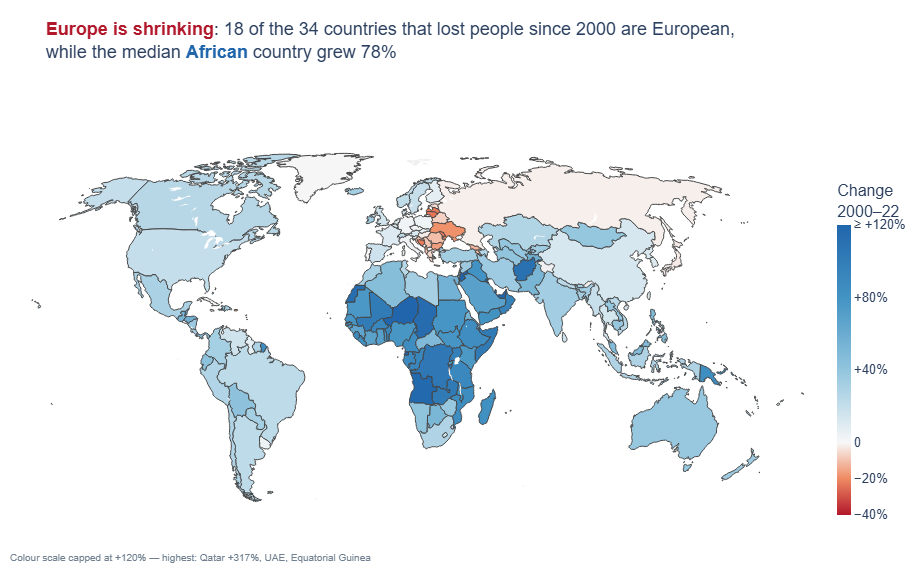

In [10]:
# Q5
q5 = df.assign(Change=(df['2022 Population'] / df['2000 Population'] - 1) * 100)
shrank = q5.loc[q5['Change'] < 0]
n_shrank, n_europe = len(shrank), (shrank['Continent'] == 'Europe').sum()
africa_median = q5.loc[q5['Continent'] == 'Africa', 'Change'].median()
print(f'{n_shrank} shrank, {n_europe} of them in Europe; median African growth {africa_median:.0f}%')
print(q5.nlargest(3, 'Change')[['Country', 'Change']].round(0))

lo, hi = -40, 120
mid = (0 - lo) / (hi - lo)                                # where 0 % sits on the 0–1 colour scale
diverging = [[0, '#B2182B'], [mid / 2, '#EF8A62'], [mid, '#F7F7F7'],
             [mid + (1 - mid) / 3, '#92C5DE'], [mid + 2 * (1 - mid) / 3, '#4393C3'], [1, '#2166AC']]

fig = px.choropleth(
    data_frame=q5,
    locations='CCA3', locationmode='ISO-3',
    color='Change',
    color_continuous_scale=diverging,
    range_color=[lo, hi],
    hover_name='Country',
    hover_data={'CCA3': False, 'Change': ':+.1f', '2000 Population': ':,', '2022 Population': ':,'},
    labels={'Change': 'Change 2000–2022 (%)'},
    title=(f"<span style='color:#B2182B'><b>Europe is shrinking</b></span>: {n_europe} of the {n_shrank} countries that lost "
           f"people since 2000 are European,<br>while the median <span style='color:#2166AC'><b>African</b></span> "
           f"country grew {africa_median:.0f}%"),
    template='plotly_white',
    height=560, width=1050,
)

fig.add_annotation(xref='paper', yref='paper', x=0.01, y=0.02, showarrow=False, align='left',
                   text=f"Colour scale capped at +{hi}% — highest: Qatar +{q5['Change'].max():.0f}%, UAE, Equatorial Guinea",
                   font=dict(size=10, color='slategrey'))

fig.update_layout(
    font=FONT,
    geo=dict(showframe=False, showcoastlines=False, projection_type='natural earth',
             projection_rotation=dict(lon=10), lataxis_range=[-58, 85],      # centred on Europe/Africa, no Antarctica
             showland=True, landcolor='#F0F0F0'),               # territories without data in light grey
    coloraxis_colorbar=dict(title=dict(text='Change<br>2000–22', side='top'), thickness=14, len=0.7, y=0.45,
                            tickvals=[-40, -20, 0, 40, 80, 120],
                            ticktext=['−40%', '−20%', '0', '+40%', '+80%', '≥ +120%']),
    margin=dict(l=0, r=0, t=70, b=0),
)
fig.show()

---
## Q6 — Where do the world's 8 billion people live?

How is the **2022 world population** distributed across **continents and the countries within them**? Show both levels in one figure.

**Chart choice & justification:** *Which chart did you choose, and why? Justify design choices.

**Chart: I used treemap with the hierarchy World → Continent → Country.**

- **Why a treemap?** The question requires showing population distribution at two levels: continents and the countries within them. A treemap makes this easy to see, as each continent is represented by a block containing its countries. A stacked bar chart would struggle to display 234 countries clearly, while a pie chart wouldn't effectively show both levels.
- **Values are additive population counts** from 2022, which can be added together. This means each continent's block represents the exact total population of its countries, making a treemap suitable. Using averages or population density would not make sense for this comparison.
- **Colour:** Asia is highlighted in blue because it has the largest population, while Africa is shown in orange because it is the second-largest and fastest-growing continent. The remaining four continents are grey. The labels and white borders help distinguish the blocks, while the colours highlight where most of the world's population lives.
- **Labels show the share of the world** (`percentRoot`) rather than the raw population count. For example, "17.9%" is easier to understand at a glance than "1,425,887,337". The exact population figures are available on hover, and the white root background keeps the chart clean without adding an unnecessary border.

Continent
Asia             0.592
Africa           0.179
Europe           0.093
North America    0.075
South America    0.055
Oceania          0.006
Name: 2022 Population, dtype: float64
China + India: 35.7%


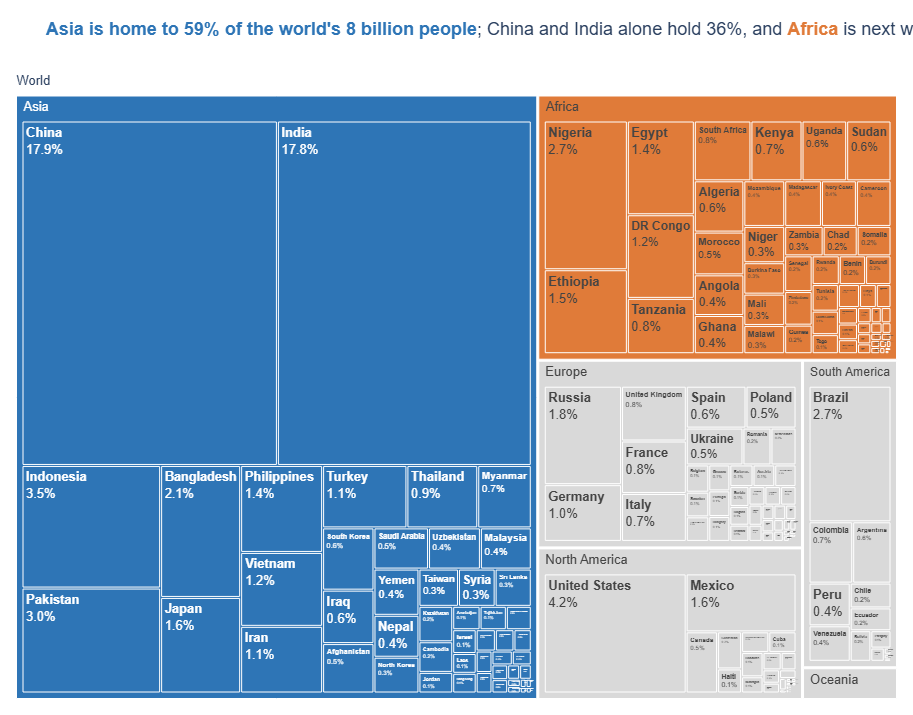

In [11]:
# Q6
world_total = df['2022 Population'].sum()
cont_share = df.groupby('Continent')['2022 Population'].sum() / world_total
china_india = df.loc[df['Country'].isin(['China', 'India']), '2022 Population'].sum() / world_total
print(cont_share.sort_values(ascending=False).round(3)); print(f'China + India: {china_india:.1%}')

grey_map = {c: LIGHT_GREY for c in df['Continent'].unique()}
grey_map.update({'Asia': ACCENT, 'Africa': AFRICA})

fig = px.treemap(
    data_frame=df,
    path=[px.Constant('World'), 'Continent', 'Country'],
    values='2022 Population',
    color='Continent',
    color_discrete_map=grey_map,
    title=(f"<span style='color:{ACCENT}'><b>Asia is home to {cont_share['Asia']:.0%} of the world's 8 billion people</b></span>; "
           f"China and India alone hold {china_india:.0%}, and "
           f"<span style='color:{AFRICA}'><b>Africa</b></span> is next with {cont_share['Africa']:.0%}"),
    template='plotly_white',
    height=700, width=1100,
)

fig.update_traces(
    root_color='white',
    texttemplate='<b>%{label}</b><br>%{percentRoot:.1%}',                       # share of world
    hovertemplate='<b>%{label}</b><br>%{value:,.0f} people<br>%{percentRoot:.1%} of world'
                  '<br>%{percentParent:.1%} of %{parent}<extra></extra>',
    marker=dict(line=dict(color='white', width=1)),
    tiling=dict(pad=2),
)

fig.data[0].marker.colors = [c if c in grey_map.values() else 'white' for c in fig.data[0].marker.colors]
fig.update_layout(font=FONT, margin=dict(l=10, r=10, t=70, b=10))
fig.show()

---
## Q7 — Whose share of the world is rising?

How have the shares of world population held by **Africa, Asia and Europe** changed from 1970 to 2022? Group the other three continents as `'Rest of the world'`.

**Chart choice & justification:** *Which chart did you choose, and why? Justify design choices.

**Chart: I used stacked bar chart, one bar per year.**

- **Why 100% stacked bars?** The question is about *shares*, the mix of a constant whole (the world = 100%) and how it changes over time. Each bar is the whole world in one year. Each segment's height is that group's share. There are only four groups, within the 2–5 segment limit where stacked bars stay readable.
- **Why not a line chart?** Lines would show each share alone but lose the part-to-whole message that the four shares always add up to 100%. Q1 already uses a line chart.
- **Segment order matches the story:** **Africa sits on the zero baseline** and **Europe sits at the top, against the 100% line**, so both stories are measured from a straight shared edge and can be read accurately. Asia and the rest of the world, which barely change, sit in the middle as floating segments.
- **Colour hierarchy:** Africa in orange (the main story, rising), Europe in dark grey (the second story, falling), Asia and the rest of the world in light greys (context). The difference in lightness also works without any colour vision.
- **Labels on Africa and Europe only**, with direct labels to the right of the 2022 bar instead of a legend. The y-axis is hidden because the shares are labelled.
- **Years as categories:** the years are unevenly spaced, so each bar is labelled with its exact year.

Group  Africa   Asia  Europe  Rest of the world
Year                                           
1970    0.099  0.581   0.178              0.143
1980    0.108  0.593   0.156              0.142
1990    0.120  0.604   0.136              0.140
2000    0.133  0.608   0.118              0.141
2010    0.151  0.604   0.105              0.139
2015    0.162  0.600   0.100              0.138
2020    0.174  0.595   0.095              0.136
2022    0.179  0.592   0.093              0.136


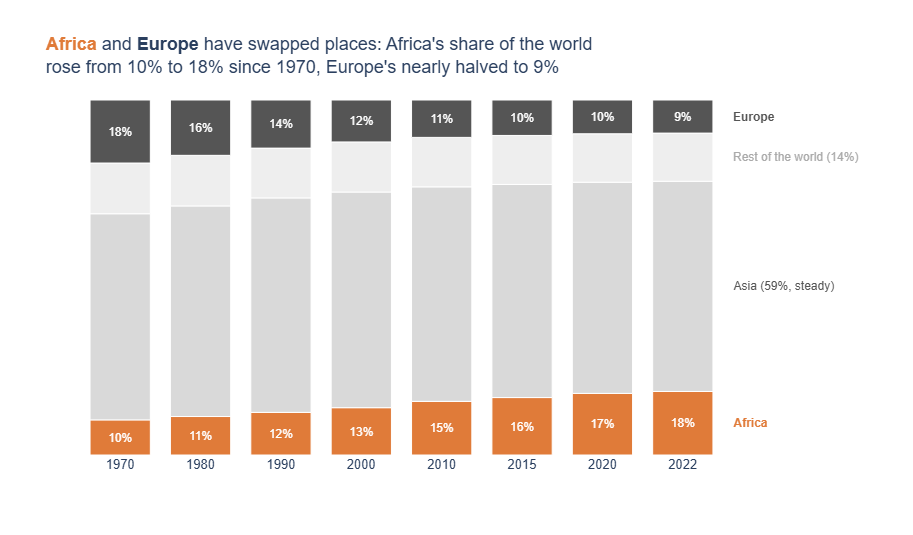

In [12]:
# Q7
groups = ['Africa', 'Asia', 'Europe']
q7 = df_long.assign(Group=df_long['Continent'].where(df_long['Continent'].isin(groups), 'Rest of the world'))
share = q7.groupby(['Year', 'Group'], as_index=False)['Population'].sum()
share['Share'] = share['Population'] / share.groupby('Year')['Population'].transform('sum')
pivot = share.pivot(index='Year', columns='Group', values='Share')
print(pivot.round(3))

share['Year'] = share['Year'].astype(str)                                   # categorical x (uneven years)
share['Label'] = np.where(share['Group'].isin(['Africa', 'Europe']), share['Share'].map('{:.0%}'.format), '')

stack_order = ['Africa', 'Asia', 'Rest of the world', 'Europe']             # Africa on baseline, Europe on top
colors = {'Africa': AFRICA, 'Asia': LIGHT_GREY, 'Rest of the world': '#EEEEEE', 'Europe': DARK_GREY}

fig = px.bar(
    data_frame=share,
    x='Year', y='Share',
    color='Group',
    text='Label',
    color_discrete_map=colors,
    category_orders={'Group': stack_order},
    hover_data={'Label': False, 'Share': ':.1%', 'Population': ':,'},
    labels={'Share': 'Share of world population', 'Group': ''},
    title=(f"<span style='color:{AFRICA}'><b>Africa</b></span> and <b>Europe</b> have swapped places: Africa's share of "
           f"the world<br>rose from {pivot.loc[1970, 'Africa']:.0%} to {pivot.loc[2022, 'Africa']:.0%} since 1970, "
           f"Europe's nearly halved to {pivot.loc[2022, 'Europe']:.0%}"),
    template='plotly_white',
    height=520, width=1000,
)

fig.update_traces(textposition='inside', insidetextanchor='middle', textfont=dict(color='white', size=12),
                  marker_line_color='white', marker_line_width=1)

# direct labels to the right of the last bar (replace the legend)
last = pivot.loc[2022, stack_order]
mids = last.cumsum() - last / 2
label_color = {'Africa': AFRICA, 'Asia': DARK_GREY, 'Rest of the world': MID_GREY, 'Europe': DARK_GREY}
for g in stack_order:
    txt = f'<b>{g}</b>' if g in ['Africa', 'Europe'] else f'{g} ({last[g]:.0%}, steady)' if g == 'Asia' else f'{g} ({last[g]:.0%})'
    fig.add_annotation(xref='paper', x=1, y=mids[g], text=txt,           # just right of the plot area
                       showarrow=False, xanchor='left', xshift=8,
                       font=dict(color=label_color[g], size=12))

fig.update_layout(
    showlegend=False,
    font=FONT,
    bargap=0.25,
    margin=dict(r=190),
    xaxis=dict(title='', showgrid=False, type='category'),   # years look numeric: force categories
    yaxis=dict(visible=False, range=[0, 1]),
)
fig.show()